In [1]:
import tensorflow as tf
print("TensorFlow version:", tf.__version__)

gpu = tf.config.list_physical_devices('GPU')
print("GPU available:", gpu)

TensorFlow version: 2.21.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.preprocessing.image import ImageDataGenerator

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
import tensorflow_datasets as tfds

dataset, info = tfds.load(
    "pneumonia",
    with_info=True,
    as_supervised=True
)

print(info)

DatasetNotFoundError: Dataset pneumonia not found.
Available datasets:
	- abstract_reasoning
	- accentdb
	- aeslc
	- aflw2k3d
	- ag_news_subset
	- ai2_arc
	- ai2_arc_with_ir
	- ai2dcaption
	- aloha_mobile
	- amazon_us_reviews
	- anli
	- answer_equivalence
	- arc
	- asimov_dilemmas_auto_val
	- asimov_dilemmas_scifi_train
	- asimov_dilemmas_scifi_val
	- asimov_injury_val
	- asimov_multimodal_auto_val
	- asimov_multimodal_manual_val
	- asimov_v2_constraints_with_rationale
	- asimov_v2_constraints_without_rationale
	- asimov_v2_injuries
	- asimov_v2_videos
	- asqa
	- asset
	- assin2
	- asu_table_top_converted_externally_to_rlds
	- austin_buds_dataset_converted_externally_to_rlds
	- austin_sailor_dataset_converted_externally_to_rlds
	- austin_sirius_dataset_converted_externally_to_rlds
	- bair_robot_pushing_small
	- bc_z
	- bccd
	- beans
	- bee_dataset
	- beir
	- berkeley_autolab_ur5
	- berkeley_cable_routing
	- berkeley_fanuc_manipulation
	- berkeley_gnm_cory_hall
	- berkeley_gnm_recon
	- 

In [5]:
!pip -q install kagglehub


In [6]:
import kagglehub
print("KaggleHub installed successfully!")

KaggleHub installed successfully!


In [7]:
import kagglehub

path = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")

print("Dataset downloaded to:", path)

Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.
Dataset downloaded to: /kaggle/input/chest-xray-pneumonia


In [8]:
import os

for root, dirs, files in os.walk(path):
    level = root.replace(path, '').count(os.sep)
    print('  ' * level + os.path.basename(root) + '/')

    if level >= 2:
        dirs[:] = []


chest-xray-pneumonia/
  chest_xray/
    chest_xray/
    __MACOSX/
    val/
    test/
    train/


In [9]:
import os

DATA_DIR = os.path.join(path, "chest_xray", "chest_xray")

train_dir = os.path.join(DATA_DIR, "train")
test_dir = os.path.join(DATA_DIR, "test")
val_dir = os.path.join(DATA_DIR, "val")

print("Train:", os.listdir(train_dir))
print("Test:", os.listdir(test_dir))
print("Validation:", os.listdir(val_dir))

Train: ['PNEUMONIA', 'NORMAL', '.DS_Store']
Test: ['PNEUMONIA', 'NORMAL', '.DS_Store']
Validation: ['PNEUMONIA', 'NORMAL', '.DS_Store']


In [10]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=10,
    zoom_range=0.1,
    horizontal_flip=True
)

test_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

train_data = train_datagen.flow_from_directory(
    train_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="binary",
    classes=["NORMAL", "PNEUMONIA"]
)

val_data = test_datagen.flow_from_directory(
    val_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="binary",
    classes=["NORMAL", "PNEUMONIA"]
)

test_data = test_datagen.flow_from_directory(
    test_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="binary",
    classes=["NORMAL", "PNEUMONIA"],
    shuffle=False
)

print("Image preprocessing completed!")

Found 5216 images belonging to 2 classes.
Found 16 images belonging to 2 classes.
Found 624 images belonging to 2 classes.
Image preprocessing completed!


In [11]:
base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False

x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dropout(0.3)(x)
output = Dense(1, activation="sigmoid")(x)

model = Model(inputs=base_model.input, outputs=output)

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


KeyboardInterrupt: 

In [12]:
base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False

model = tf.keras.Sequential([
    base_model,
    GlobalAveragePooling2D(),
    Dropout(0.3),
    Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("Model successfully created!")


Model successfully created!


In [13]:
history = model.fit(
    train_data,
    epochs=2,
    validation_data=val_data
)

Epoch 1/2
163/163 ━━━━━━━━━━━━━━━━━━━━ 209s 1s/step - accuracy: 0.8637 - loss: 0.3238 - val_accuracy: 0.8125 - val_loss: 0.3969
Epoch 2/2
163/163 ━━━━━━━━━━━━━━━━━━━━ 196s 845ms/step - accuracy: 0.9406 - loss: 0.1591 - val_accuracy: 0.8125 - val_loss: 0.4103


In [14]:
test_loss, test_accuracy = model.evaluate(test_data)

print("\nTest Loss:", test_loss)
print("Test Accuracy:", round(test_accuracy * 100, 2), "%")


20/20 ━━━━━━━━━━━━━━━━━━━━ 13s 512ms/step - accuracy: 0.7901 - loss: 0.4531

Test Loss: 0.45307204127311707
Test Accuracy: 79.01 %


In [15]:
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

predictions = model.predict(test_data)

predicted_classes = (predictions > 0.5).astype(int).flatten()
actual_classes = test_data.classes

print("Classification Report:\n")
print(classification_report(
    actual_classes,
    predicted_classes,
    target_names=["NORMAL", "PNEUMONIA"]
))

20/20 ━━━━━━━━━━━━━━━━━━━━ 15s 513ms/step
Classification Report:

              precision    recall  f1-score   support

      NORMAL       0.97      0.45      0.62       234
   PNEUMONIA       0.75      0.99      0.86       390

    accuracy                           0.79       624
   macro avg       0.86      0.72      0.74       624
weighted avg       0.83      0.79      0.77       624



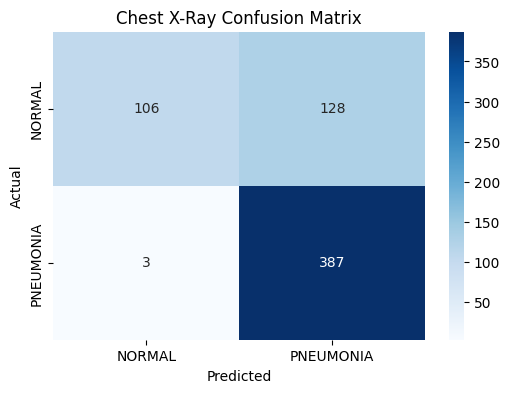

In [16]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(actual_classes, predicted_classes)

plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["NORMAL", "PNEUMONIA"],
            yticklabels=["NORMAL", "PNEUMONIA"])

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Chest X-Ray Confusion Matrix")
plt.show()

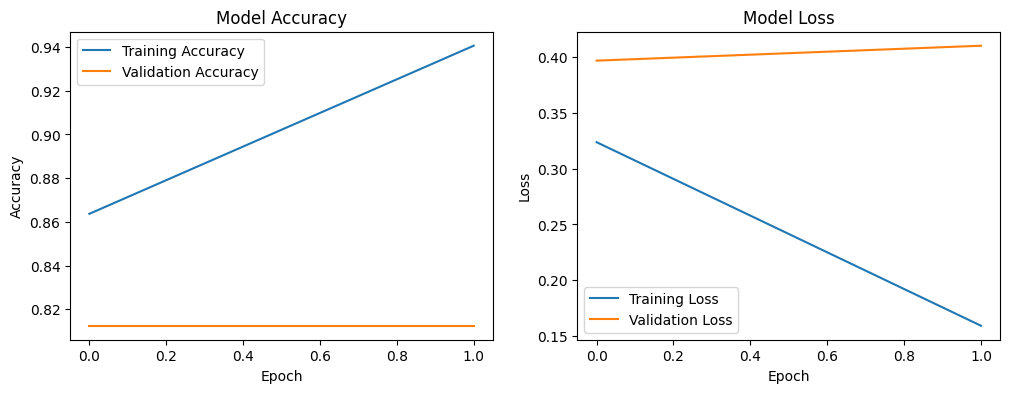

In [17]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.show()

In [18]:
from google.colab import files
from tensorflow.keras.utils import load_img, img_to_array

uploaded = files.upload()

for filename in uploaded.keys():
    img = load_img(filename, target_size=(224, 224))
    img_array = img_to_array(img)
    img_array = preprocess_input(img_array)
    img_array = np.expand_dims(img_array, axis=0)

    prediction = model.predict(img_array)[0][0]

    if prediction >= 0.5:
        print("Prediction: PNEUMONIA")
    else:
        print("Prediction: NORMAL")

Saving sample_x-ray.jpg to sample_x-ray.jpg
1/1 ━━━━━━━━━━━━━━━━━━━━ 14s 14s/step
Prediction: PNEUMONIA
